In [1]:
import os
import gc
import glob
import random
import warnings
from datetime import datetime

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2

import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms

from PIL import Image
from PIL import Image as PILImage
from tqdm.auto import tqdm

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import preprocess_image

from lime import lime_image
import shap

import quantus
from quantus import MaxSensitivity, norm_func, similarity_func
import matplotlib.pyplot as plt

from xai_lib import MemoryManagement as mm
from xai_lib import AttributionEngine as att_engine

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(SEED)


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Fixed 224x224 inputs -> let cuDNN pick the fastest conv algorithms
torch.backends.cudnn.benchmark = True

Using device: cuda


In [4]:
name = "aveera"

In [5]:
IDRID_DIR = f"/data/{name}/Refined IDRiD"
IDRID_SPLIT_DIRS = [
    os.path.join(IDRID_DIR, "Test", "Test"),
    os.path.join(IDRID_DIR, "Train", "Train"),
]

drive_model_dir = f"/data/{name}/models"
RESULTS_DIR = f"/data/{name}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (
        f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR."
    )
print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")


Using Refined IDRiD data from '/data/aveera/Refined IDRiD' (Test + Train splits)


**Loading and pre-processing Refined IDRiD**

In [6]:
# Pixel values of all lesion classes (background + anatomical structures excluded)
LESION_LABEL_IDS = {
    4,    # Vitreous Hemorrhage (VH)
    63,   # Hard Exudate (EX)
    96,   # IRMA
    127,  # Hemorrhage (HE)
    166,  # Neovascularization (NV)
    191,  # Cotton-Wool Spot (CWS)
    255,  # Microaneurysm (MA)
}


In [7]:
def resize_mask_no_loss(mask, target_size):
    mask_f = mask.astype(np.float32)
    coverage = cv2.resize(mask_f, target_size, interpolation=cv2.INTER_AREA)
    # any nonzero coverage in the box -> lesion touched that region
    return (coverage > 0).astype(np.uint8)

def load_and_preprocess(split_dirs, target_size=(224, 224), max_images=None):

    samples = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        labels_dir = os.path.join(split_dir, "Labels")

        image_paths = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))
        for img_path in image_paths:
            if split_dir == os.path.normpath(f"/data/{name}/Refined IDRiD/Train/Train"): 
              image_id = os.path.splitext(os.path.basename(img_path))[0]+"_vessel"
            else:
              image_id = os.path.splitext(os.path.basename(img_path))[0] 

            mask_path = os.path.join(labels_dir, f"{image_id}.png")
            if not os.path.isfile(mask_path):
                continue

            raw_mask = np.array(Image.open(mask_path).convert('L'))
            raw_img = np.array(Image.open(img_path).convert('RGB'))

            # Resizes the lesion mask if the height and width aren't the same as the original image
            if raw_mask.shape[:2] != raw_img.shape[:2]:
                raw_mask = cv2.resize(raw_mask, (raw_img.shape[1], raw_img.shape[0]),interpolation=cv2.INTER_NEAREST)

            green_channel = raw_img[:, :, 1] 

            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            enhanced_green = clahe.apply(green_channel) 

            bgr_enhanced = cv2.merge([enhanced_green, enhanced_green, enhanced_green]) # Merge into a clean 3-channel layout 
            
            rgb_enhanced = cv2.cvtColor(bgr_enhanced, cv2.COLOR_BGR2RGB)

            img_resized = cv2.resize(rgb_enhanced, (224, 224), interpolation=cv2.INTER_CUBIC)# Resize the image

            # Keep only lesion pixels and exclude background and the 4 anatomical classes
            lesion_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

            mask_resized = resize_mask_no_loss(lesion_mask, target_size)

            samples.append((img_resized, mask_resized))

            if max_images is not None and len(samples) >= max_images:
                return samples
        print("There are ", len(samples)," images in ", split_dir)

    return samples

In [8]:
# MaxSensitivity only needs the first N_TEST samples (same value as the original notebook),
# so we cap the load here instead of loading every split image into RAM.
N_TEST = 81

idrid_subset = load_and_preprocess(IDRID_SPLIT_DIRS, max_images=N_TEST)
print(f"Loaded {len(idrid_subset)} IDRiD images (capped at N_TEST={N_TEST})")

maxsens_samples = idrid_subset[:N_TEST]


There are  27  images in  /data/aveera/Refined IDRiD/Test/Test


Loaded 81 IDRiD images (capped at N_TEST=81)


**Model loading**

In [9]:
def load_model(model_name, weight_path, device):
    if model_name == "resnet50":
        model = models.resnet50(weights=None)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    elif model_name == "efficientnetb0":
        model = models.efficientnet_b0(weights=None)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    model.load_state_dict(torch.load(weight_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model


In [10]:
_engine_cache = {}

def get_engine_for(model):
    """Look up the AttributionEngine that was built for this exact model object."""
    eng = _engine_cache.get(id(model))
    if eng is None:
        raise RuntimeError("No AttributionEngine registered for this model.")
    return eng


In [11]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


def get_predicted_labels(model, samples, device, transform=test_transform):
    preds = []
    model.eval()
    with torch.no_grad():
        for raw_img_np, _ in samples:
            input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to(device)
            pred = model(input_tensor).argmax(dim=1).item()
            preds.append(pred)
    return np.array(preds)


**Complexity xai functions**

In [12]:
def explain_gradcam(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        gradcam = eng.compute_gradcam(img_tensor.unsqueeze(0).to(eng.device), int(target))
        maps.append(gradcam)
    return np.stack(maps)[:, None, :, :]


def explain_lime(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        raw = eng.unnormalize_to_uint8(img_tensor)
        explanation = eng.compute_lime(raw, int(target))
        heatmap = eng.get_lime_heatmap(explanation, int(target))
        maps.append(heatmap)
        eng.close_lime_explanation(explanation)
        del explanation
    return np.stack(maps)[:, None, :, :]


def explain_shap(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        raw = eng.unnormalize_to_uint8(img_tensor)
        shap_values = eng.compute_shap(raw, target_class=int(target), all_classes=False)
        heatmap, _ = eng.get_shap_heatmap(shap_values, class_position=0)
        maps.append(heatmap)
    return np.stack(maps)[:, None, :, :]


# Kept as an ordered dict-of-one so we can loop "one method at a time" deliberately below
explain_funcs = {
    "GradCAM": explain_gradcam,
    "LIME": explain_lime,
    "SHAP": explain_shap,
}


**Complexity configuration loop**

In [13]:
MODEL_NAMES = ["resnet50", "efficientnetb0"]
METHOD_NAMES = ["GradCAM", "LIME", "SHAP"] 

COMPLEXITY_RESULT = os.path.join(RESULTS_DIR, "complexity_per_image.csv")
COLS = ["model","method","image_index","complexity"]

In [14]:
def save_row(row):
    pd.DataFrame([row],columns = COLS).to_csv(COMPLEXITY_RESULT, mode = "a", header= not os.path.exists(COMPLEXITY_RESULT), index = False)

done = pd.read_csv(COMPLEXITY_RESULT) if os.path.exists(COMPLEXITY_RESULT) else pd.DataFrame(columns=COLS)
done_keys = set(zip(done["model"], done["method"], done["image_index"]))

In [15]:
for model_name in MODEL_NAMES:
    print(f"\n===== {model_name} =====")

    #Loading model
    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device,)
    _engine_cache[id(model)] = engine

    x_batch_all = np.stack([
        preprocess_image(img.astype(np.float32) / 255.0, mean=[0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225]).squeeze(0).numpy()
        for img, _ in maxsens_samples
    ])

    y_batch_all = get_predicted_labels(model, maxsens_samples, device)
    mm.gpu_mem_report(f"after loading {model_name}")

    # Process one xai method at a time to avoid OOM errors
    for method in METHOD_NAMES:
        print(f"\n  Method: {method} ({model_name})")

        explain_func = explain_funcs[method]
        metric = quantus.Complexity()
        set_seed(SEED)

        for img_idx in tqdm(range(len(x_batch_all)), desc = f"{model_name}/{method}"):
            
            # Isolating one image from the batch of images to run our test on
            x_single = x_batch_all[img_idx:img_idx + 1]
            y_single = y_batch_all[img_idx:img_idx + 1]

            if (model_name, method,img_idx) in done_keys:
                continue

            row = dict(model=model_name,method=method,image_index=img_idx,complexity=np.nan)

            try:
                a_single = explain_func(model, x_single, y_single)

                score = metric(model=model,
                               x_batch = x_single,
                               y_batch = y_single,
                               a_batch = a_single,
                               device = device,
                               explain_func=explain_func
                               )[0]  #it's returned as a list, so we index by 0 to grab the first element of the list as a float

                row["complexity"] = float(score)

            except AssertionError as e:
                print(f"{model_name} had a degenerate explanation on image {img_idx} for {method}: {e}")
            
            except Exception as e:
                print(f"    Error on {model_name}/{method}/image {img_idx}: {e}")
                continue

            save_row(row)

            if img_idx % 10 ==0:
                mm.clear_memory()

        del metric
        mm.clear_memory()

    del x_batch_all, y_batch_all

    # Clear the model completely before loading the next one
    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name}")



===== resnet50 =====


[mem after loading resnet50] allocated=0.10 GB  reserved=0.16 GB

  Method: GradCAM (resnet50)



  Method: LIME (resnet50)



  Method: SHAP (resnet50)


  0%|          | 0/498 [00:00<?, ?it/s]

...

 95%|█████████▌| 474/498 [00:03<00:00, 259.41it/s]

524it [00:03, 285.91it/s]                         

PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:14, 14.29s/it]               

[mem after unloading efficientnetb0] allocated=0.02 GB  reserved=0.04 GB


In [16]:
full_complexity_df = pd.read_csv(COMPLEXITY_RESULT)

MAX_ENTROPY = np.log(224*224)

summary = (full_complexity_df.groupby(["model","method"])
           .agg(mean_complexity=("complexity","mean"),
                std_complexity=("complexity","std"),
                median_complexity=("complexity","median"),
                n_valid=("complexity","count"),
                n_failed=("complexity", lambda s: s.isna().sum()))
                .reset_index())

summary["mean_complexity_norm"]=summary["mean_complexity"]/MAX_ENTROPY
summary = summary.round(4)
display(summary)
summary.to_csv(os.path.join(RESULTS_DIR,"complexity_summary.csv"), index=False)

,model,method,mean_complexity,std_complexity,median_complexity,n_valid,n_failed,mean_complexity_norm
0,efficientnetb0,GradCAM,10.3775,0.2023,10.4041,81,0,0.9588
1,efficientnetb0,LIME,9.9302,0.1852,9.9471,81,0,0.9175
2,efficientnetb0,SHAP,9.9928,0.2286,10.0113,81,0,0.9233
3,resnet50,GradCAM,10.2403,0.2267,10.2706,81,0,0.9461
4,resnet50,LIME,9.7820,0.2568,9.7978,81,0,0.9038
5,resnet50,SHAP,9.8254,0.3389,9.8056,81,0,0.9078


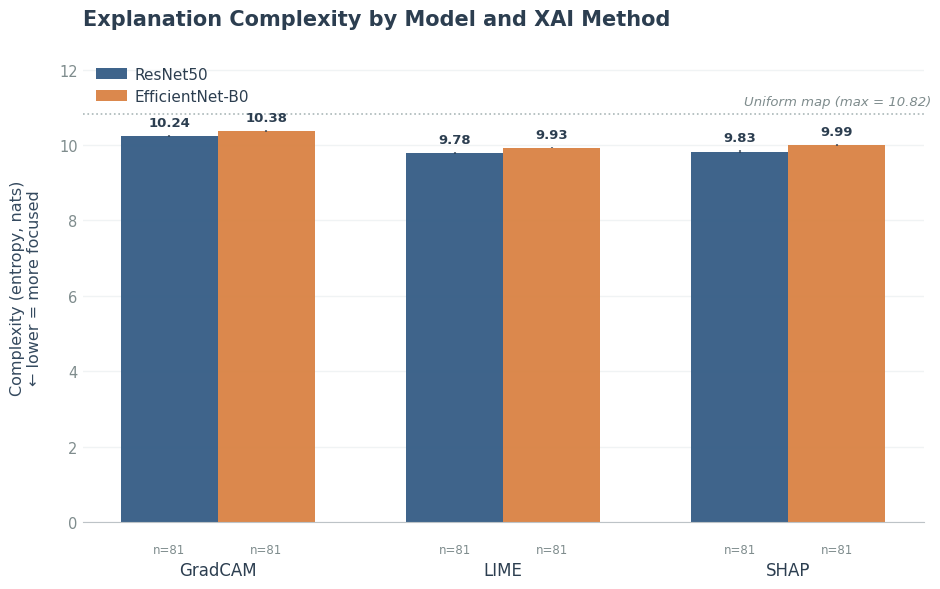

In [17]:
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]

colors = {"resnet50": "#345C85", "efficientnetb0": "#D98243"}
pretty = {"resnet50": "ResNet50", "efficientnetb0": "EfficientNet-B0"}
methods = ["GradCAM", "LIME", "SHAP"]
models = ["resnet50", "efficientnetb0"]

plot_df = summary.copy()
plot_df["sem"] = plot_df["std_complexity"] / np.sqrt(plot_df["n_valid"])
lookup = plot_df.set_index(["model", "method"])

fig, ax = plt.subplots(figsize=(9.5, 6), facecolor="white")
ax.set_facecolor("white")

x = np.arange(len(methods))
width = 0.34

for i, m in enumerate(models):
    means = [
        lookup.loc[(m, meth), "mean_complexity"]
        if (m, meth) in lookup.index
        else np.nan
        for meth in methods
    ]
    sems = [
        lookup.loc[(m, meth), "sem"] if (m, meth) in lookup.index else np.nan
        for meth in methods
    ]
    ns = [
        int(lookup.loc[(m, meth), "n_valid"])
        if (m, meth) in lookup.index
        else 0
        for meth in methods
    ]

    pos = x + (i - 0.5) * width

    bars = ax.bar(
        pos,
        means,
        width,
        yerr=sems,
        capsize=0,
        label=pretty[m],
        color=colors[m],
        alpha=0.95,
        error_kw=dict(ecolor="#2C3E50", elinewidth=1.5, alpha=0.7),
    )

    for b, mean, sem, n in zip(bars, means, sems, ns):
        if np.isnan(mean):
            continue

        y_pos = mean + sem + (MAX_ENTROPY * 0.015)
        ax.text(
            b.get_x() + b.get_width() / 2,
            y_pos,
            f"{mean:.2f}",
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="semibold",
            color="#2C3E50",
        )

        ax.text(
            b.get_x() + b.get_width() / 2,
            -(MAX_ENTROPY * 0.05),
            f"n={n}",
            ha="center",
            va="top",
            fontsize=8.5,
            color="#7F8C8D",
        )

ax.axhline(
    MAX_ENTROPY, color="#95A5A6", linestyle=":", linewidth=1.2, alpha=0.8
)
ax.text(
    len(methods) - 0.5,
    MAX_ENTROPY + (MAX_ENTROPY * 0.015),
    f"Uniform map (max = {MAX_ENTROPY:.2f})",
    ha="right",
    va="bottom",
    fontsize=9.5,
    color="#7F8C8D",
    fontstyle="italic",
)

ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=12, color="#2C3E50")
ax.tick_params(axis="x", pad=28)

ax.yaxis.grid(True, color="#F0F3F4", linewidth=1.0)
ax.set_axisbelow(True)

for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#BDC3C7")
ax.spines["bottom"].set_linewidth(0.8)

ax.set_ylabel(
    "Complexity (entropy, nats)\n← lower = more focused",
    fontsize=11.5,
    color="#34495E",
    labelpad=12,
)
ax.set_title(
    "Explanation Complexity by Model and XAI Method",
    fontsize=15,
    fontweight="bold",
    color="#2C3E50",
    pad=20,
    loc="left",
)

ax.set_ylim(0, MAX_ENTROPY * 1.15)
ax.tick_params(axis="y", colors="#7F8C8D", labelsize=10.5, length=0)
ax.tick_params(axis="x",pad=28,length=0)

ax.legend(
    frameon=False,
    fontsize=11,
    loc="upper left",
    labelcolor="#2C3E50",
    handletextpad=0.5,
)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "complexity_barchart.png"),
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
